# Anatomical Data Analysis
This notebook analyzes anatomical quantitative data, specifically focusing on the ratio of Bundle Sheath (BS) to Mesophyll (M) area ($V_{BS/M}$) across different photosynthetic types (C3, C3-C4, C4).

In [1]:
# Import necessary libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from utils import *
from statannotations.Annotator import Annotator
from IPython.display import HTML
from scipy.stats import gaussian_kde
from scipy.stats import mannwhitneyu, normaltest

## Data Loading and Preprocessing
Load the dataset and clean the relevant anatomical columns by handling missing values and converting data types.

In [2]:
# Load the dataset
data = pd.read_csv("../Datasets/Anatomical_Quantitative_Analysis.csv")
total_samples = len(data)
print(f"Total number of samples (rows): {total_samples}")

# Clean anatomical columns: replace hyphens with NaN and convert to float
data['AW_M'] = data['AW_M'].replace('-', np.nan).astype("float")
data['AW_BS'] = data['AW_BS'].replace('-', np.nan).astype("float")
data['AW_BS/AW_M'] = data['AW_BS/AW_M'].replace('-', np.nan).astype("float")

# Filter out rows where the ratio is NaN
data = data[data['AW_BS/AW_M'].notna()]

# Display the first few rows
total_samples = len(data)
print(f"Total number of usable samples (rows): {total_samples}")
print()
print(data.head())

Total number of samples (rows): 202
Total number of usable samples (rows): 130

                                        Bibliography  Sample  \
0  Sonawane, B.V., Koteyeva, N.K., Johnson, D.M. ...       1   
1  Yorimitsu Y, Kadosono A, Hatakeyama Y, Yabiku ...       1   
2  Yorimitsu Y, Kadosono A, Hatakeyama Y, Yabiku ...       2   
4  Yorimitsu Y, Kadosono A, Hatakeyama Y, Yabiku ...       8   
5  Yorimitsu Y, Kadosono A, Hatakeyama Y, Yabiku ...      12   

                  Species PHT LS(TLS/PLS)     AW_M   AW_BS  AW_BS/AW_M  \
0      Panicum bisulcatum  C3         TLS  146.040  74.923    0.513031   
1  Chenopodium atrovirens  C3         TLS  218.710  95.700    0.437566   
2    Chenopodium vulvaria  C3         TLS   89.305  51.007    0.571155   
4    Chenopodium vulvaria  C3         TLS   93.280  40.465    0.433801   
5       Chenopodium hians  C3         TLS  187.010  97.770    0.522806   

           ID  
0   SK_2021_1  
1   YK_2019_1  
2   YK_2019_2  
4   YK_2019_8  
5  YK_2019

## Distribution of Photosynthetic Types
Count the number of entries for each photosynthetic type (PHT).

In [3]:
data_counts = data["PHT"].value_counts()
print(data_counts)

PHT
C4       51
C3-C4    48
C3       31
Name: count, dtype: int64


## Bibliographic and Species Statistics
Calculate the total number of unique publications and species included in the analysis.

In [4]:
# Count unique species per photosynthetic type
unique_species_per_type = data.groupby("PHT")["Species"].nunique()
print("\n--- Unique Species Count per Photosynthetic Type ---")
print(unique_species_per_type)

# Unique counts for Bibliography and Overall Species
print("\n--- Dataset Summary ---")
print("Number of publications: {}".format(data["Bibliography"].nunique())) 
print("Number of unique Species: {}".format(data["Species"].nunique()))


--- Unique Species Count per Photosynthetic Type ---
PHT
C3       25
C3-C4    28
C4       31
Name: Species, dtype: int64

--- Dataset Summary ---
Number of publications: 18
Number of unique Species: 84


## Statistical Analysis of Anatomical Constraints
This section handles outlier removal, statistical testing, and visualization of the $V_{BS/M}$ ratio.

### Outlier Removal Function
Define a helper function to remove outliers based on the Interquartile Range (IQR) method.

In [5]:
def remove_outliers(data, column, label):
    """
    Removes outliers from a dataframe based on IQR.
    Returns the filtered dataframe and prints statistics.
    """
    # Calculate IQR bounds
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Remove outliers
    filtered = data[(data[column] >= lower_bound) & (data[column] <= upper_bound)]

    # Compute post-filtering stats
    Q1_f = filtered[column].quantile(0.25)
    Q3_f = filtered[column].quantile(0.75)
    IQR_f = Q3_f - Q1_f
    min_f = filtered[column].min()
    max_f = filtered[column].max()

    # Print results
    print(f"\n--- {label} (AFTER OUTLIER REMOVAL) ---")
    print(f"Number of rows before filtering: {len(data)}")
    print(f"Number of rows after filtering: {len(filtered)}")
    print(f"Number of outliers removed: {len(data) - len(filtered)}")
    print(f"Q1: {Q1_f}")
    print(f"Q3: {Q3_f}")
    print(f"IQR: {IQR_f}")
    print(f"Minimum: {min_f}")
    print(f"Maximum: {max_f}")

    return filtered

### Data Filtering
Split the data by photosynthetic type and apply outlier removal.

In [6]:
# Split by photosynthetic type
c3 = data[data['PHT'] == "C3"]
c3_c4 = data[data['PHT'] == "C3-C4"]
c4 = data[data['PHT'] == "C4"]

# Remove outliers from 'AW_BS/AW_M' and show stats after filtering
data_clean_c3_awbs_awm_without_outliers = remove_outliers(c3, 'AW_BS/AW_M', 'C3')
data_clean_c3_c4_awbs_awm_without_outliers = remove_outliers(c3_c4, 'AW_BS/AW_M', 'C3-C4')
data_clean_c4_awbs_awm_without_outliers = remove_outliers(c4, 'AW_BS/AW_M', 'C4')

print("\n--- Summary of Species Count After Outlier Removal ---")
print("C3 Species:", len(data_clean_c3_awbs_awm_without_outliers))
print("C3-C4 Species:", len(data_clean_c3_c4_awbs_awm_without_outliers))
print("C4 Species:", len(data_clean_c4_awbs_awm_without_outliers))


--- C3 (AFTER OUTLIER REMOVAL) ---
Number of rows before filtering: 31
Number of rows after filtering: 30
Number of outliers removed: 1
Q1: 0.511123245975
Q3: 1.14305602125
IQR: 0.631932775275
Minimum: 0.198285051
Maximum: 2.137871287

--- C3-C4 (AFTER OUTLIER REMOVAL) ---
Number of rows before filtering: 48
Number of rows after filtering: 44
Number of outliers removed: 4
Q1: 0.7277088663
Q3: 1.66746259275
IQR: 0.93975372645
Minimum: 0.3247238214
Maximum: 3.549173554

--- C4 (AFTER OUTLIER REMOVAL) ---
Number of rows before filtering: 51
Number of rows after filtering: 47
Number of outliers removed: 4
Q1: 1.246340425
Q3: 2.1788636295
IQR: 0.9325232044999998
Minimum: 0.6746078722
Maximum: 3.766259321

--- Summary of Species Count After Outlier Removal ---
C3 Species: 30
C3-C4 Species: 44
C4 Species: 47


### Statistical Testing (Mann-Whitney U)
Perform Mann-Whitney U tests to compare the distributions between different photosynthetic types.

In [7]:
# Mann-Whitney tests
stat_results_aw_bs_aw_m_without_outliers = [
    mannwhitneyu(data_clean_c3_awbs_awm_without_outliers["AW_BS/AW_M"],
                 data_clean_c3_c4_awbs_awm_without_outliers["AW_BS/AW_M"],
                 alternative="two-sided"),
    mannwhitneyu(data_clean_c3_c4_awbs_awm_without_outliers["AW_BS/AW_M"],
                 data_clean_c4_awbs_awm_without_outliers["AW_BS/AW_M"],
                 alternative="two-sided"),
    mannwhitneyu(data_clean_c3_awbs_awm_without_outliers["AW_BS/AW_M"],
                 data_clean_c4_awbs_awm_without_outliers["AW_BS/AW_M"],
                 alternative="two-sided")
]

print("\n--- Mann-Whitney Test Results for AW_BS/AW_M (Without Outliers) ---")
print("C3 vs C3-C4:", stat_results_aw_bs_aw_m_without_outliers[0])
print("C3-C4 vs C4:", stat_results_aw_bs_aw_m_without_outliers[1])
print("C3 vs C4:", stat_results_aw_bs_aw_m_without_outliers[2])


--- Mann-Whitney Test Results for AW_BS/AW_M (Without Outliers) ---
C3 vs C3-C4: MannwhitneyuResult(statistic=np.float64(439.0), pvalue=np.float64(0.01519804429238127))
C3-C4 vs C4: MannwhitneyuResult(statistic=np.float64(569.0), pvalue=np.float64(0.00022514845358225332))
C3 vs C4: MannwhitneyuResult(statistic=np.float64(157.0), pvalue=np.float64(1.07171127533485e-08))


### Visualization
Generate boxplots with statistical annotations to visualize the differences in $V_{BS/M}$.

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

C3 vs. C3-C4: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:1.520e-02 U_stat=4.390e+02
C3-C4 vs. C4: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:2.251e-04 U_stat=5.690e+02
C3 vs. C4: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:1.072e-08 U_stat=1.570e+02


/tmp/ipykernel_21211/1387186079.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(**plotting_parameters, ax=ax, showfliers=False)


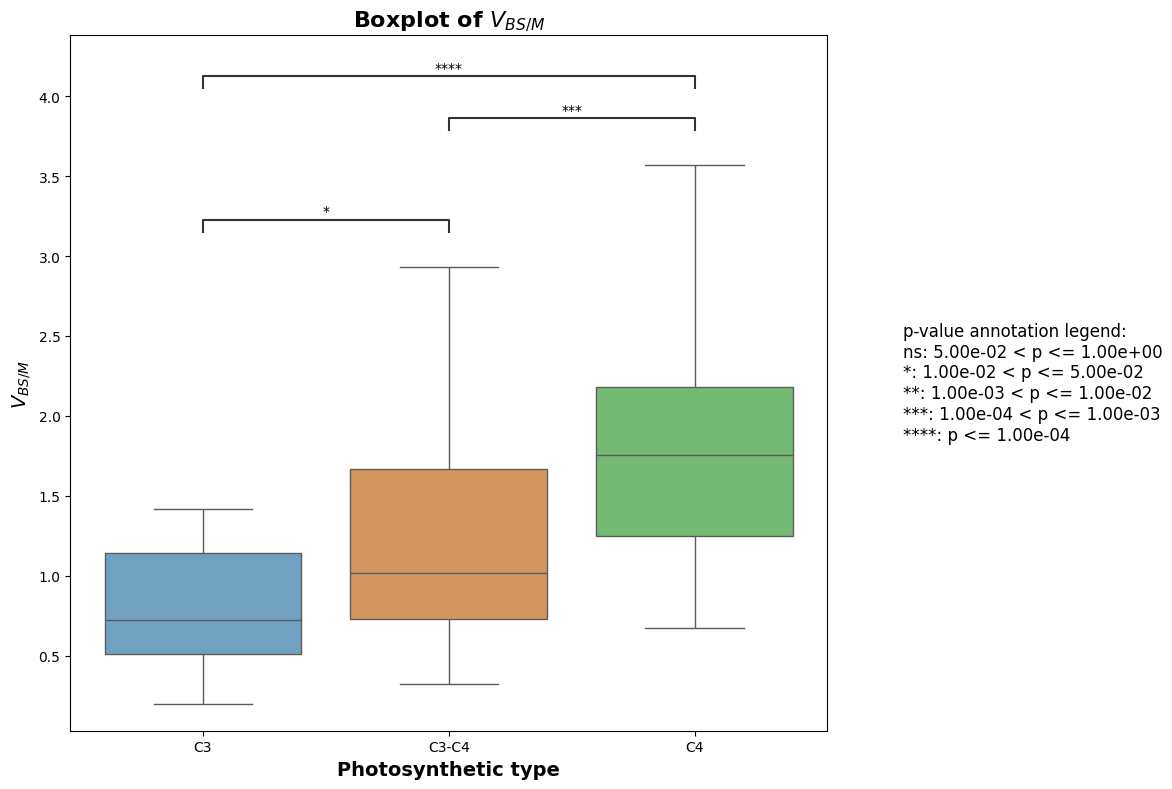

In [8]:
# Combine for plotting
data_clean_combined_awbs_awm_without_outliers = pd.concat(
    [data_clean_c3_awbs_awm_without_outliers,
     data_clean_c3_c4_awbs_awm_without_outliers,
     data_clean_c4_awbs_awm_without_outliers],
    ignore_index=True
)

# Plotting parameters
pairs = [('C3', 'C3-C4'), ('C3-C4', 'C4'), ('C3', 'C4')]
category_order = ['C3', 'C3-C4', 'C4']
color_map = {'C3': '#64a4ceff', 'C3-C4': '#e6954cfb', 'C4': '#69c569fe'}

plotting_parameters = {
    'data': data_clean_combined_awbs_awm_without_outliers,
    'x': 'PHT',
    'y': 'AW_BS/AW_M',
    'order': category_order,
    'palette': color_map 
}

# Create figure
fig, ax = plt.subplots(figsize=(12, 8))
sns.boxplot(**plotting_parameters, ax=ax, showfliers=False)

# Add statistical annotations
annotator = Annotator(ax, pairs, **plotting_parameters)
annotator.configure(test="Mann-Whitney", comparisons_correction="BH")
_, corrected_results = annotator.apply_and_annotate()

# Add custom legend for p-values
legend_text = ("p-value annotation legend:\n"
               "ns: 5.00e-02 < p <= 1.00e+00\n"
               "*: 1.00e-02 < p <= 5.00e-02\n"
               "**: 1.00e-03 < p <= 1.00e-02\n"
               "***: 1.00e-04 < p <= 1.00e-03\n"
               "****: p <= 1.00e-04")

plt.text(1.1, 0.5, legend_text, transform=ax.transAxes,
         fontsize=12, va='center', ha='left')

# Final formatting
plt.title("Boxplot of $V_{BS/M}$", fontsize=16, fontweight='bold')
ax.set_ylabel("$V_{BS/M}$", fontsize=14, fontweight='bold')
ax.set_xlabel("Photosynthetic type", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## Data Export
Save the processed data to a CSV file (optional).

In [9]:
#data_clean_combined_awbs_awm_without_outliers.to_csv('Final_Boxplot_No_Outliers.csv', index=False)